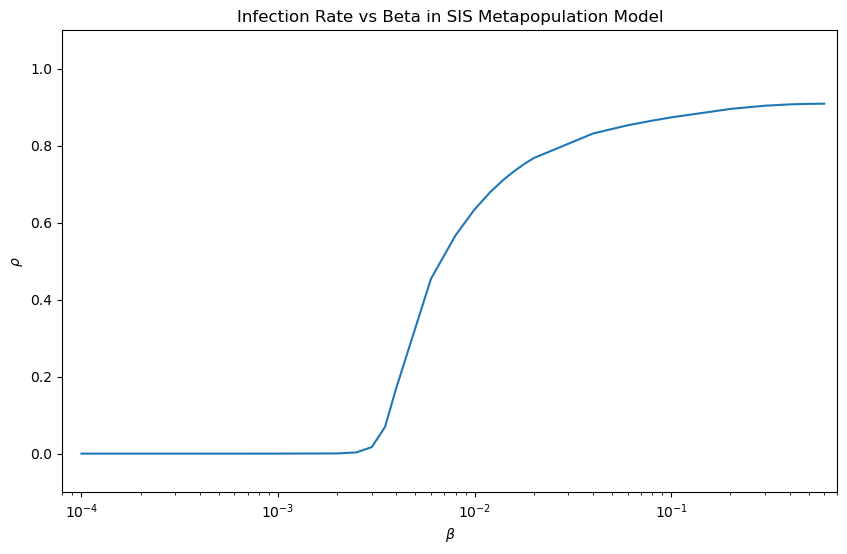

In [6]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
import random

# 设置随机种子以确保结果可复现
np.random.seed(42)
random.seed(42)

# 生成小世界网络并为每条边分配1到10之间的随机权重，返回邻接矩阵W
def generate_small_world_network(N, k, p_rewire):
    G = nx.watts_strogatz_graph(N, k, p_rewire)
    for u, v in G.edges():
        G[u][v]['weight'] = random.randint(1, 10)
    W = nx.to_numpy_array(G, weight='weight')
    return W

# 计算C矩阵
def calculate_C_matrix(W):
    N = W.shape[0]
    C = np.zeros_like(W, dtype=float)
    for i in range(N):
        row_sum = np.sum(W[i, :])
        if row_sum > 0:
            C[i, :] = W[i, :] / row_sum
    return C

# 生成每个子种群的网络并计算平均度
def generate_subpopulations(N):
    n = np.random.randint(50, 101, size=N)  # 每个节点的初始人口
    average_degrees = n * 0.1
    return n, average_degrees

# 运行模拟实验
def run_simulation(beta, N, initial_infected_density, n, average_degrees, C, mu, p_move, alpha, steps):

    rho = np.full(N, initial_infected_density)
    # R_i = np.zeros(N)
    # D_i = np.zeros(N)
    # P_i = np.zeros(N)
    # Pi_i = np.zeros(N)
    for t in range(steps):
        new_rho = np.zeros(N)
        R_i = np.zeros(N)
        D_i = np.zeros(N)
        P_i = np.zeros(N)
        Pi_i = np.zeros(N)
        for i in range(N):
            R_i[i] = 1 - (1 - beta) ** ((1 - p_move) * average_degrees[i] * rho[i] +
                                     np.sum([p_move * C[j, i] * average_degrees[j] * rho[j] for j in range(N)]))
            D_i[i] = 1 - (1 - beta) ** ((1 - p_move) * n[i] * rho[i] +
                                     np.sum([p_move * C[j, i] * n[j] * rho[j] for j in range(N)]))
            P_i[i] = alpha * R_i[i] + (1 - alpha) * D_i[i]
        for i in range(N):
            Pi_i[i] = (1 - p_move) * P_i[i] + p_move * np.sum([C[i, j] * P_i[j] for j in range(N)])
            new_rho[i] = (1 - mu) * rho[i] + (1 - rho[i]) * Pi_i[i]
        rho = new_rho
    return np.mean(rho)


# 初始变量
N = 20
k = 8
p_rewire = 0.8
initial_infected_density = 0.01

mu = 0.1
p_move = 0.1
alpha = 0.6
steps = 100

# 方法一：生成小世界网络
W = generate_small_world_network(N, k, p_rewire)

# 方法二：计算C矩阵
C = calculate_C_matrix(W)

# 方法三：生成每个子种群的网络并计算平均度
n, average_degrees = generate_subpopulations(N)


# 方法四：生成不同区间的 beta 值
beta_values = np.concatenate([
    np.arange(0.0001, 0.001, 0.0003),
    np.arange(0.001, 0.002, 0.001),
    np.arange(0.002, 0.003, 0.0005),
    np.arange(0.003, 0.004, 0.0005),
    np.arange(0.004, 0.01, 0.002),
    np.arange(0.01, 0.02, 0.002),
    np.arange(0.02, 0.1, 0.02),
    np.arange(0.1, 0.7, 0.1)
])


# 记录每个 beta 值对应的感染率
rho_end_values = [run_simulation(beta, N, initial_infected_density, n, average_degrees, C, mu, p_move, alpha, steps) for beta in beta_values]

# 绘制结果
plt.figure(figsize=(10, 6))
plt.plot(beta_values, rho_end_values, marker='o')
plt.xlabel(r"$\beta$")
plt.ylabel(r"$\rho$")
plt.title("Infection Rate vs Beta in SIS Metapopulation Model")
plt.xscale("log")
plt.yscale("linear")
plt.ylim(-0.1, 1.1)  # 设置y轴范围
plt.yticks(np.arange(0.0, 1.1, 0.2))
plt.xticks([0.0001, 0.001, 0.01, 0.1], ["$10^{-4}$", "$10^{-3}$", "$10^{-2}$", "$10^{-1}$"])
plt.xlim(0.00008, 0.7)  # 设置x轴范围
# plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.show()


In [10]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
import random

# 设置随机种子以确保结果可复现
np.random.seed(42)
random.seed(42)

# 生成小世界网络并为每条边分配1到10之间的随机权重，返回邻接矩阵W
def generate_small_world_network(N, k, p_rewire):
    G = nx.watts_strogatz_graph(N, k, p_rewire)
    for u, v in G.edges():
        G[u][v]['weight'] = random.randint(1, 10)
    W = nx.to_numpy_array(G, weight='weight')
    return W

# 计算C矩阵
def calculate_C_matrix(W):
    N = W.shape[0]
    C = np.zeros_like(W, dtype=float)
    for i in range(N):
        row_sum = np.sum(W[i, :])
        if row_sum > 0:
            C[i, :] = W[i, :] / row_sum
    return C

# 生成每个子种群的网络并计算平均度
def generate_subpopulations(N):
    n = np.full(N, 100)
    average_degrees = n * 0.05
    return n, average_degrees

# 运行模拟实验
def run_simulation(beta, N, initial_infected_density, n, average_degrees, C, mu, p_move, alpha, steps):

    rho = np.full(N, initial_infected_density)
    # R_i = np.zeros(N)
    # D_i = np.zeros(N)
    # P_i = np.zeros(N)
    # Pi_i = np.zeros(N)
    for t in range(steps):
        new_rho = np.zeros(N)
        R_i = np.zeros(N)
        D_i = np.zeros(N)
        P_i = np.zeros(N)
        Pi_i = np.zeros(N)
        for i in range(N):
            R_i[i] = 1 - (1 - beta) ** ((1 - p_move) * average_degrees[i] * rho[i] +
                                     np.sum([p_move * C[j, i] * average_degrees[j] * rho[j] for j in range(N)]))
            D_i[i] = 1 - (1 - beta) ** ((1 - p_move) * n[i] * rho[i] +
                                     np.sum([p_move * C[j, i] * n[j] * rho[j] for j in range(N)]))
            P_i[i] = alpha * R_i[i] + (1 - alpha) * D_i[i]
        for i in range(N):
            Pi_i[i] = (1 - p_move) * P_i[i] + p_move * np.sum([C[i, j] * P_i[j] for j in range(N)])
            new_rho[i] = (1 - mu) * rho[i] + (1 - rho[i]) * Pi_i[i]
        rho = new_rho
    return np.mean(rho)


# 初始变量
N = 10
k = 5
p_rewire = 0.8
initial_infected_density = 0.01

mu = 0.1

alpha = 0.6
steps = 100

# 方法一：生成小世界网络
W = generate_small_world_network(N, k, p_rewire)

# 方法二：计算C矩阵
C = calculate_C_matrix(W)

# 方法三：生成每个子种群的网络并计算平均度
n, average_degrees = generate_subpopulations(N)


# 方法四：生成不同区间的 beta 值
beta_values = 0.0035
p_move = 0.1

# 记录每个 beta 值对应的感染率
rho_end_values = run_simulation(beta_values, N, initial_infected_density, n, average_degrees, C, mu, p_move, alpha, steps)

# 绘制结果
print("beta:", beta_values)
print("p_move:", p_move)
print("rho_end_values:", rho_end_values)


beta: 0.0035
rho_end_values: 0.2555001525597052


无重复实验的MMCA实验 基于不同p值

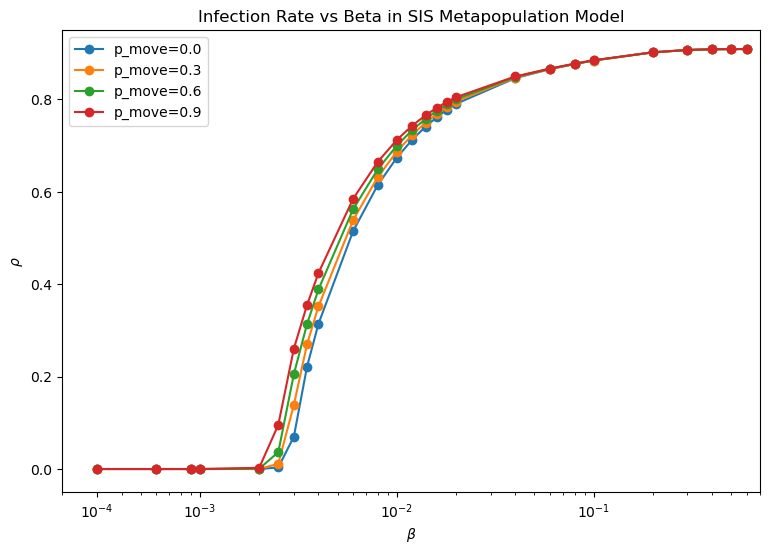

In [2]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
import random
import pandas as pd

# 设置随机种子以确保结果可复现
np.random.seed(42)
random.seed(42)

# 生成小世界网络并为每条边分配1到10之间的随机权重，返回邻接矩阵W
def generate_small_world_network(N, k, p_rewire):
    G = nx.watts_strogatz_graph(N, k, p_rewire)
    for u, v in G.edges():
        G[u][v]['weight'] = random.randint(1, 10)
    W = nx.to_numpy_array(G, weight='weight')
    return W

# 计算C矩阵
def calculate_C_matrix(W):
    N = W.shape[0]
    C = np.zeros_like(W, dtype=float)
    for i in range(N):
        row_sum = np.sum(W[i, :])
        if row_sum > 0:
            C[i, :] = W[i, :] / row_sum
    return C

# 生成每个子种群的网络并计算平均度
def generate_subpopulations(N):
    # n = np.random.randint(50, 101, size=N)  # 每个节点的初始人口
    n = np.full(N, 100)
    average_degrees = n * 0.1
    return n, average_degrees

# 运行模拟实验
def run_simulation(beta, N, initial_infected_density, n, average_degrees, C, mu, p_move, alpha, steps):
    rho = np.full(N, initial_infected_density)
    for t in range(steps):
        new_rho = np.zeros(N)
        R_i = np.zeros(N)
        D_i = np.zeros(N)
        P_i = np.zeros(N)
        Pi_i = np.zeros(N)
        for i in range(N):
            R_i[i] = 1 - (1 - beta) ** ((1 - p_move) * average_degrees[i] * rho[i] +
                                     np.sum([p_move * C[j, i] * average_degrees[j] * rho[j] for j in range(N)]))
            D_i[i] = 1 - (1 - beta) ** ((1 - p_move) * n[i] * rho[i] * 0.8 +
                                     np.sum([p_move * C[j, i] * n[j] * rho[j] for j in range(N)]))
            P_i[i] = alpha * R_i[i] + (1 - alpha) * D_i[i]
        for i in range(N):
            Pi_i[i] = (1 - p_move) * P_i[i] + p_move * np.sum([C[i, j] * P_i[j] for j in range(N)])
            new_rho[i] = (1 - mu) * rho[i] + (1 - rho[i]) * Pi_i[i]
        rho = new_rho
    return np.mean(rho)

# 初始变量
N = 20
k = 8
p_rewire = 0.8
initial_infected_density = 0.01

mu = 0.1
alpha = 0.6
steps = 200

# 方法一：生成小世界网络
W = generate_small_world_network(N, k, p_rewire)

# 方法二：计算C矩阵
C = calculate_C_matrix(W)

# 方法三：生成每个子种群的网络并计算平均度
n, average_degrees = generate_subpopulations(N)

# 方法四：生成不同区间的 beta 值
beta_values = np.concatenate([
    np.arange(0.0003, 0.001, 0.0003),
    np.arange(0.001, 0.002, 0.001),
    np.arange(0.002, 0.003, 0.0005),
    np.arange(0.003, 0.004, 0.0005),
    np.arange(0.004, 0.01, 0.002),
    np.arange(0.01, 0.02, 0.002),
    np.arange(0.02, 0.1, 0.02),
    np.arange(0.1, 0.7, 0.1)
])

# 不同的移动概率值
p_move_values = [0.0, 0.3, 0.6, 0.9]

# 记录不同p_move值下的结果
results = {}

for p_move in p_move_values:
    rho_end_values = [run_simulation(beta, N, initial_infected_density, n, average_degrees, C, mu, p_move, alpha, steps) for beta in beta_values]
    results[p_move] = rho_end_values

# 转换results为DataFrame并保存到CSV文件
df = pd.DataFrame(results, index=beta_values)
df.index.name = 'beta'
df.to_csv('0716simulation_results2.csv')

# 绘制结果
plt.figure(figsize=(9, 6))
for p_move, rho_end_values in results.items():
    plt.plot(beta_values, rho_end_values, marker='o', label=f'p_move={p_move}')
plt.xlabel(r"$\beta$")
plt.ylabel(r"$\rho$")
plt.title("Infection Rate vs Beta in SIS Metapopulation Model")
plt.xscale("log")
plt.yscale("linear")
plt.ylim(-0.05, 0.95)  # 设置y轴范围
plt.yticks(np.arange(0.0, 0.95, 0.2))
plt.xticks([0.0003, 0.001, 0.01, 0.1], ["$10^{-4}$", "$10^{-3}$", "$10^{-2}$", "$10^{-1}$"])
plt.xlim(0.0002, 0.7)  # 设置x轴范围
plt.legend()
# plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.show()